# 4. Final Evaluation and Model Interpretation

This notebook evaluates the selected CNN checkpoint on the untouched official test set. It reports imbalance-aware metrics, analyzes class-level errors, reviews model confidence, and uses Grad-CAM to visualize spatial evidence behind selected predictions.

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)


current_dir = Path.cwd()

if (current_dir / "data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Project root not found. Open Jupyter from the "
        "'wafer-map-defect-classification' folder."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "figures"

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Evaluation device:", DEVICE)
print("Project root:", PROJECT_ROOT)

Evaluation device: mps
Project root: <LOCAL_PATH>


## 4.1 Load the Test Set and Selected Model

In [5]:
from src.data_loading import load_wm811k
from src.preprocessing import preprocess_wafer_map
from src.model import WaferMapCNN


wm811k = load_wm811k(
    RAW_DATA_DIR / "WM811K_source.zip"
)

test_manifest = pd.read_csv(
    PROCESSED_DATA_DIR / "test_manifest.csv"
)

with open(
    PROCESSED_DATA_DIR / "class_mapping.json",
    "r",
    encoding="utf-8",
) as file:
    class_to_index = json.load(file)

CLASS_NAMES = [
    class_name
    for class_name, class_index in sorted(
        class_to_index.items(),
        key=lambda item: item[1],
    )
]

checkpoint_path = MODEL_DIR / "best_wafer_map_cnn.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False,
)

model = WaferMapCNN(
    num_classes=len(CLASS_NAMES)
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Raw dataset shape:", wm811k.shape)
print("Test samples:", len(test_manifest))
print("Loaded checkpoint epoch:", checkpoint["epoch"])
print(
    "Checkpoint validation macro F1:",
    f"{checkpoint['validation_macro_f1']:.4f}",
)
print("Class order:", CLASS_NAMES)

Raw dataset shape: (811457, 6)
Test samples: 118595
Loaded checkpoint epoch: 7
Checkpoint validation macro F1: 0.7041
Class order: ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-full', 'Random', 'Scratch', 'none']


## 4.2 Generate Predictions on the Official Test Set

In [6]:
class WaferMapDataset(Dataset):
    """Provide preprocessed wafer maps and labels to PyTorch."""

    def __init__(self, manifest, raw_data):
        self.manifest = manifest.reset_index(drop=True)
        self.raw_data = raw_data

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, index):
        row = self.manifest.iloc[index]

        source_index = int(row["source_index"])
        wafer_map = self.raw_data.at[source_index, "waferMap"]

        image = preprocess_wafer_map(wafer_map)

        label = torch.tensor(
            int(row["label_index"]),
            dtype=torch.long,
        )

        return image, label


test_dataset = WaferMapDataset(
    test_manifest,
    wm811k,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0,
)

print("Number of test batches:", len(test_loader))

Number of test batches: 464


In [7]:
all_true_labels = []
all_predictions = []
all_confidences = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)

        confidences, predictions = probabilities.max(dim=1)

        all_true_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_confidences.extend(
            confidences.cpu().numpy()
        )

all_true_labels = np.asarray(all_true_labels)
all_predictions = np.asarray(all_predictions)
all_confidences = np.asarray(all_confidences)

test_results = test_manifest.copy()

test_results["predicted_index"] = all_predictions
test_results["predicted_class"] = [
    CLASS_NAMES[index]
    for index in all_predictions
]

test_results["confidence"] = all_confidences
test_results["is_correct"] = (
    test_results["label_index"].to_numpy()
    == all_predictions
)

print("Number of generated predictions:", len(test_results))
print("Mean prediction confidence:",
      f"{test_results['confidence'].mean():.4f}")

Number of generated predictions: 118595
Mean prediction confidence: 0.7897


In [8]:
from sklearn.metrics import balanced_accuracy_score


test_accuracy = accuracy_score(
    all_true_labels,
    all_predictions,
)

test_macro_f1 = f1_score(
    all_true_labels,
    all_predictions,
    average="macro",
    zero_division=0,
)

test_weighted_f1 = f1_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0,
)

test_balanced_accuracy = balanced_accuracy_score(
    all_true_labels,
    all_predictions,
)

print("Official test results")
print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Macro F1:          {test_macro_f1:.4f}")
print(f"Weighted F1:       {test_weighted_f1:.4f}")
print(f"Balanced accuracy: {test_balanced_accuracy:.4f}")

Official test results
Accuracy:          0.9438
Macro F1:          0.4160
Weighted F1:       0.9286
Balanced accuracy: 0.3821


## 4.3 Analyze Class-Level Performance

In [9]:
report = classification_report(
    all_true_labels,
    all_predictions,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

report_table = (
    pd.DataFrame(report)
    .transpose()
    .loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]]
)

report_table["support"] = report_table["support"].astype(int)

display(
    report_table.style.format(
        {
            "precision": "{:.3f}",
            "recall": "{:.3f}",
            "f1-score": "{:.3f}",
            "support": "{:d}",
        }
    )
)

report_table.to_csv(
    MODEL_DIR / "test_classification_report.csv"
)

print(
    "Classification report saved to:",
    MODEL_DIR / "test_classification_report.csv",
)

,precision,recall,f1-score,support
Center,0.160,0.062,0.090,832
Donut,0.167,0.007,0.013,146
Edge-Loc,0.624,0.263,0.370,2772
Edge-Ring,0.732,0.588,0.652,1126
Loc,0.574,0.031,0.060,1973
Near-full,0.864,0.937,0.899,95
Random,0.874,0.541,0.668,257
Scratch,0.023,0.014,0.018,693
none,0.955,0.995,0.975,110701


Classification report saved to: <LOCAL_PATH>


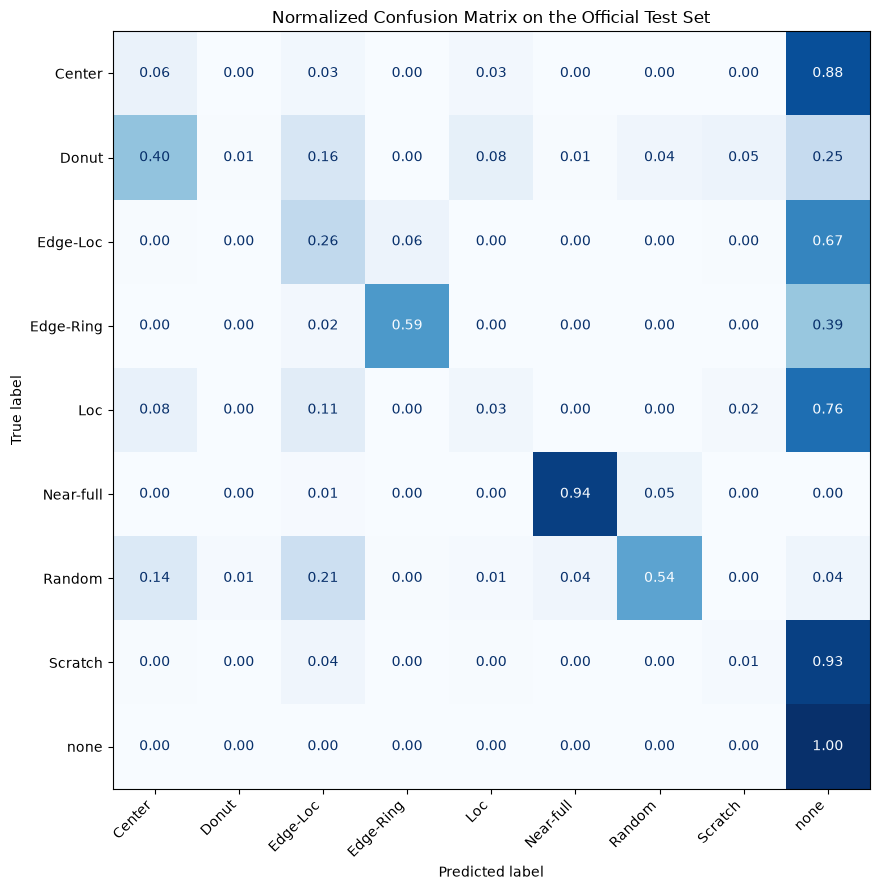

Confusion matrix saved to: <LOCAL_PATH>


In [10]:
from sklearn.metrics import ConfusionMatrixDisplay


normalized_confusion_matrix = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=list(range(len(CLASS_NAMES))),
    normalize="true",
)

fig, ax = plt.subplots(figsize=(10, 9))

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=normalized_confusion_matrix,
    display_labels=CLASS_NAMES,
)

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    colorbar=False,
)

ax.set_title(
    "Normalized Confusion Matrix on the Official Test Set"
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

confusion_matrix_path = (
    FIGURES_DIR / "04_test_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Confusion matrix saved to:", confusion_matrix_path)

In [11]:
count_confusion_matrix = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=list(range(len(CLASS_NAMES))),
)

confusion_rows = []

for true_index, true_class in enumerate(CLASS_NAMES):
    class_counts = count_confusion_matrix[true_index].copy()
    class_counts[true_index] = 0

    confused_indices = np.argsort(class_counts)[::-1][:2]
    true_support = count_confusion_matrix[true_index].sum()

    for rank, predicted_index in enumerate(confused_indices, start=1):
        confused_count = class_counts[predicted_index]

        confusion_rows.append(
            {
                "true_class": true_class,
                "rank": rank,
                "confused_with": CLASS_NAMES[predicted_index],
                "count": int(confused_count),
                "percentage_of_true_class": (
                    confused_count / true_support * 100
                ),
            }
        )

top_confusions = pd.DataFrame(confusion_rows)

display(
    top_confusions.style.format(
        {
            "percentage_of_true_class": "{:.1f}%"
        }
    )
)

top_confusions.to_csv(
    MODEL_DIR / "top_test_confusions.csv",
    index=False,
)

,true_class,rank,confused_with,count,percentage_of_true_class
0,Center,1,none,729,87.6%
1,Center,2,Edge-Loc,24,2.9%
2,Donut,1,Center,59,40.4%
3,Donut,2,none,36,24.7%
4,Edge-Loc,1,none,1844,66.5%
5,Edge-Loc,2,Edge-Ring,160,5.8%
6,Edge-Ring,1,none,435,38.6%
7,Edge-Ring,2,Edge-Loc,28,2.5%
8,Loc,1,none,1490,75.5%
9,Loc,2,Edge-Loc,222,11.3%


## 4.4 Analyze Prediction Confidence and Review Workload

In [12]:
confidence_summary = (
    test_results
    .groupby("is_correct")["confidence"]
    .agg(["count", "mean", "median", "min", "max"])
)

confidence_summary.index = [
    "Incorrect" if not value else "Correct"
    for value in confidence_summary.index
]

display(confidence_summary)

REVIEW_THRESHOLD = 0.70

test_results["review_required"] = (
    test_results["confidence"] < REVIEW_THRESHOLD
)

number_of_errors = (~test_results["is_correct"]).sum()

number_of_reviewed_errors = (
    (~test_results["is_correct"])
    & test_results["review_required"]
).sum()

review_rate = test_results["review_required"].mean()

error_capture_rate = (
    number_of_reviewed_errors / number_of_errors
)

accepted_results = test_results[
    ~test_results["review_required"]
]

accepted_accuracy = accepted_results[
    "is_correct"
].mean()

print(f"Illustrative review threshold: {REVIEW_THRESHOLD:.2f}")
print(f"Fraction sent for review: {review_rate:.2%}")
print(f"Fraction of errors captured: {error_capture_rate:.2%}")
print(f"Accuracy among accepted predictions: {accepted_accuracy:.2%}")

review_rate_by_class = (
    test_results
    .groupby("failure_type")["review_required"]
    .mean()
    .reindex(CLASS_NAMES)
    .to_frame("review_rate")
)

display(
    review_rate_by_class.style.format(
        {"review_rate": "{:.1%}"}
    )
)

test_results.to_csv(
    MODEL_DIR / "test_predictions.csv",
    index=False,
)

,count,mean,median,min,max
Incorrect,6660,0.620366,0.644107,0.213281,0.991480
Correct,111935,0.799794,0.812710,0.233935,0.999597


Illustrative review threshold: 0.70
Fraction sent for review: 22.11%
Fraction of errors captured: 61.80%
Accuracy among accepted predictions: 97.25%


,review_rate
failure_type,
Center,50.5%
Donut,93.2%
Edge-Loc,62.5%
Edge-Ring,41.7%
Loc,64.0%
Near-full,10.5%
Random,59.5%
Scratch,44.4%
none,19.6%


## 4.5 Visualize Model Attention with Grad-CAM

In [13]:
class GradCAM:
    """Generate a Grad-CAM heatmap from a selected convolutional layer."""

    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self._save_activations
        )

        self.backward_handle = target_layer.register_full_backward_hook(
            self._save_gradients
        )

    def _save_activations(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_index):
        self.model.eval()
        self.model.zero_grad()

        logits = self.model(input_tensor)
        target_score = logits[0, class_index]

        target_score.backward()

        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True,
        )

        heatmap = (
            weights * self.activations
        ).sum(dim=1, keepdim=True)

        heatmap = torch.relu(heatmap)

        heatmap = torch.nn.functional.interpolate(
            heatmap,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )

        heatmap = heatmap.squeeze()
        heatmap = heatmap - heatmap.min()

        if heatmap.max() > 0:
            heatmap = heatmap / heatmap.max()

        return heatmap.cpu().numpy()

    def close(self):
        self.forward_handle.remove()
        self.backward_handle.remove()

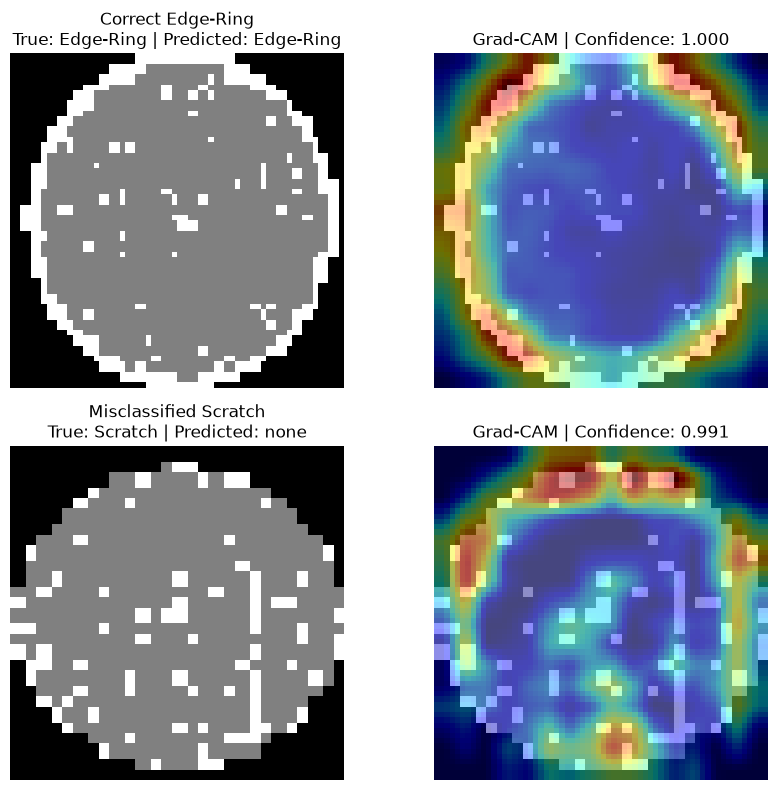

Grad-CAM figure saved to: <LOCAL_PATH>


In [14]:
correct_example = (
    test_results[
        (test_results["is_correct"])
        & (test_results["failure_type"] == "Edge-Ring")
    ]
    .sort_values("confidence", ascending=False)
    .iloc[0]
)

incorrect_example = (
    test_results[
        (~test_results["is_correct"])
        & (test_results["failure_type"] == "Scratch")
        & (test_results["predicted_class"] == "none")
    ]
    .sort_values("confidence", ascending=False)
    .iloc[0]
)

selected_examples = [
    ("Correct Edge-Ring", correct_example),
    ("Misclassified Scratch", incorrect_example),
]

grad_cam = GradCAM(
    model=model,
    target_layer=model.features[8],
)

fig, axes = plt.subplots(2, 2, figsize=(9, 8))

for row_number, (description, example) in enumerate(selected_examples):
    source_index = int(example["source_index"])
    original_map = wm811k.at[source_index, "waferMap"]

    input_tensor = preprocess_wafer_map(
        original_map
    ).unsqueeze(0).to(DEVICE)

    predicted_index = int(example["predicted_index"])

    heatmap = grad_cam.generate(
        input_tensor,
        predicted_index,
    )

    processed_image = (
        input_tensor
        .squeeze()
        .detach()
        .cpu()
        .numpy()
    )

    axes[row_number, 0].imshow(
        processed_image,
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[row_number, 0].set_title(
        f"{description}\n"
        f"True: {example['failure_type']} | "
        f"Predicted: {example['predicted_class']}"
    )

    axes[row_number, 0].axis("off")

    axes[row_number, 1].imshow(
        processed_image,
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[row_number, 1].imshow(
        heatmap,
        cmap="jet",
        alpha=0.45,
    )

    axes[row_number, 1].set_title(
        f"Grad-CAM | Confidence: "
        f"{example['confidence']:.3f}"
    )

    axes[row_number, 1].axis("off")

grad_cam.close()

plt.tight_layout()

gradcam_path = FIGURES_DIR / "05_gradcam_examples.png"

plt.savefig(
    gradcam_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Grad-CAM figure saved to:", gradcam_path)

## 4.6 Save Final Evaluation Results

In [15]:
final_metrics = {
    "test_samples": int(len(test_results)),
    "accuracy": float(test_accuracy),
    "macro_f1": float(test_macro_f1),
    "weighted_f1": float(test_weighted_f1),
    "balanced_accuracy": float(test_balanced_accuracy),
    "illustrative_review_threshold": float(REVIEW_THRESHOLD),
    "review_rate": float(review_rate),
    "error_capture_rate": float(error_capture_rate),
    "accepted_accuracy": float(accepted_accuracy),
    "best_validation_epoch": int(checkpoint["epoch"]),
    "best_validation_macro_f1": float(
        checkpoint["validation_macro_f1"]
    ),
}

with open(
    MODEL_DIR / "final_metrics.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(final_metrics, file, indent=2)

print(json.dumps(final_metrics, indent=2))

{
  "test_samples": 118595,
  "accuracy": 0.9438424891437245,
  "macro_f1": 0.41602061078473507,
  "weighted_f1": 0.9286454331980709,
  "balanced_accuracy": 0.3820946479685816,
  "illustrative_review_threshold": 0.7,
  "review_rate": 0.22111387495256968,
  "error_capture_rate": 0.618018018018018,
  "accepted_accuracy": 0.9724591867665526,
  "best_validation_epoch": 7,
  "best_validation_macro_f1": 0.7041378205970299
}


## 4.7 Final Evaluation Summary

- The selected CNN checkpoint was evaluated once on the untouched official test set containing 118,595 wafer maps.
- The model achieved 94.38% accuracy, 0.4160 macro F1, 0.9286 weighted F1, and 0.3821 balanced accuracy.
- Test accuracy must be interpreted cautiously because 93.34% of the official test samples belong to the majority `none` class.
- The model performed strongly on `Near-full` and `none`, and showed moderate performance on `Edge-Ring` and `Random`.
- Performance was poor on `Center`, `Donut`, `Loc`, and `Scratch`, with many true defect patterns incorrectly classified as `none`.
- An illustrative confidence threshold of 0.70 sent 22.11% of test wafers for review and captured 61.80% of prediction errors.
- Confidence-based review reduced risk but did not capture all errors, particularly high-confidence false negatives.
- Grad-CAM highlighted the wafer boundary for a correctly classified `Edge-Ring` example.
- For a `Scratch` example misclassified as `none`, Grad-CAM focused on the upper wafer edge rather than the actual linear defect, suggesting that the model missed the relevant spatial pattern.
- The model should be viewed as an experimental defect-pattern triage tool rather than a production-ready classifier or a root-cause diagnosis system.
- Future work should investigate spatially aware model heads, improved minority-class learning, confidence calibration, and validation on additional manufacturing datasets.